# **Import preprocessed dataset**
The preprocessing steps are in `01_preprocessing.ipynb`, which exports `datasets/preprocessed_data.csv`.

In [1]:
import pandas as pd
from pathlib import Path

data_path = Path.cwd() / "datasets" / "preprocessed_data.csv"
df_cluster = pd.read_csv(data_path)

# Exploratory Data Analysis (EDA)

### Step 4: Univariate EDA

After preprocessing, each selected variable is checked individually.

The summary method depends on the variable type.


In [2]:
numeric_vars = [
    "sc_age_years"
]

ordinal_vars = [
    "screentime",
    "sleep_hours",
    "k6q71_r",
    "higrade",
    "foodsit"
]

categorical_vars = [
    "sc_sex",
    "family_r",
    "blindness",
    "eyedoctor",
    "k4q22_r",
    "k4q23",
    "k10q12",
    "k10q13",
    "k10q14"
]

print("Numeric variables:", numeric_vars)
print("Ordinal variables:", ordinal_vars)
print("Categorical variables:", categorical_vars)


Numeric variables: ['sc_age_years']
Ordinal variables: ['screentime', 'sleep_hours', 'k6q71_r', 'higrade', 'foodsit']
Categorical variables: ['sc_sex', 'family_r', 'blindness', 'eyedoctor', 'k4q22_r', 'k4q23', 'k10q12', 'k10q13', 'k10q14']


#### Age Distribution

`sc_age_years` is numerical, so descriptive statistics and its distribution are checked.


In [3]:
df_cluster["sc_age_years"].describe()


count    51375.000000
mean         9.665499
std          5.211370
min          0.000000
25%          5.000000
50%         10.000000
75%         14.000000
max         17.000000
Name: sc_age_years, dtype: float64

In [4]:
age_counts = df_cluster["sc_age_years"].value_counts().sort_index()
print(age_counts)


sc_age_years
0     1537
1     1949
2     2870
3     2462
4     2489
5     2534
6     2203
7     2408
8     2563
9     2626
10    2860
11    2914
12    2923
13    3165
14    3459
15    3691
16    4288
17    4434
Name: count, dtype: int64


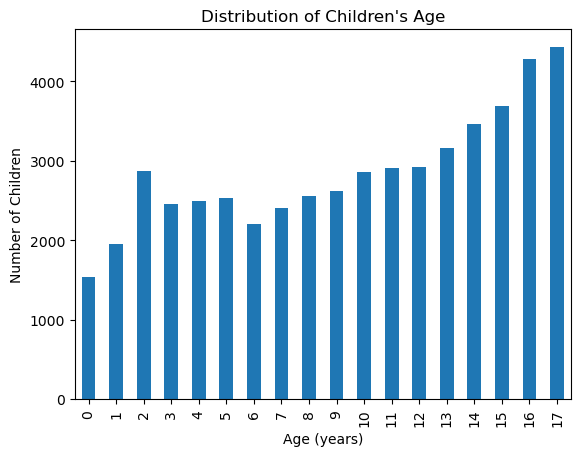

In [5]:
import matplotlib.pyplot as plt

age_counts.plot(kind="bar")
plt.xlabel("Age (years)")
plt.ylabel("Number of Children")
plt.title("Distribution of Children's Age")
plt.show()


The dataset covers ages 0–17. Older ages have more observations, so age should be considered in later comparisons.


#### Sleep Distribution

`sleep_hours` is kept as an ordered category because T1 and T2/T3 use different hour ranges for the same codes.


In [6]:
sleep_table = pd.DataFrame({
    "Count": df_cluster["sleep_hours"].value_counts().sort_index(),
    "Percentage": (
        df_cluster["sleep_hours"].value_counts(normalize=True).sort_index() * 100
    ).round(2)
})

display(sleep_table)


,Count,Percentage
sleep_hours,,
1.0,439,0.85
2.0,1578,3.07
3.0,5960,11.60
4.0,15373,29.92
5.0,13799,26.86
6.0,8891,17.31
7.0,5335,10.38


Most observations are in the middle sleep categories. The codes should not be read as exact hours.


#### Screen Time Distribution

`screentime` is the main variable in this project.

1 = Less than 1 hour, 2 = 1 hour, 3 = 2 hours, 4 = 3 hours, 5 = 4 or more hours.


In [7]:
screen_labels = {
    1.0: "Less than 1 hour",
    2.0: "1 hour",
    3.0: "2 hours",
    4.0: "3 hours",
    5.0: "4 or more hours"
}

screen_counts = df_cluster["screentime"].value_counts().sort_index()
print(screen_counts)


screentime
1.0     7257
2.0     7901
3.0    14464
4.0     9430
5.0    12323
Name: count, dtype: int64


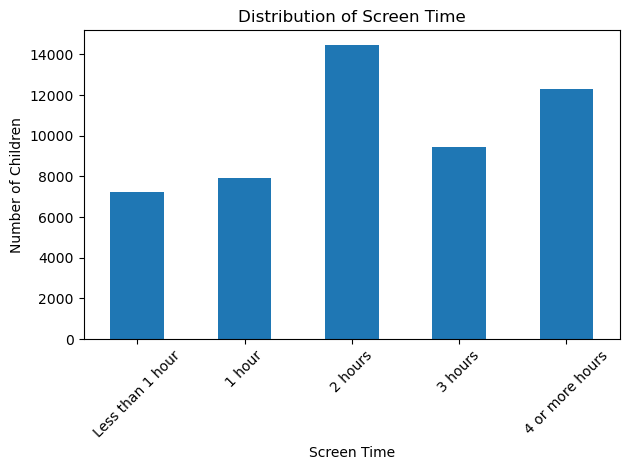

In [8]:
screen_plot = screen_counts.copy()
screen_plot.index = [screen_labels[x] for x in screen_plot.index]

screen_plot.plot(kind="bar")
plt.xlabel("Screen Time")
plt.ylabel("Number of Children")
plt.title("Distribution of Screen Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


The most common category is 2 hours, followed by 4 or more hours. All categories have enough observations for comparison.


#### Other Variables

The remaining categorical and ordinal variables are checked using frequency and percentage tables.


In [9]:
from IPython.display import display

label_maps = {
    "sc_sex": {
        1: "Male",
        2: "Female"
    },
    "family_r": {
        1.0: "Two biological/adoptive parents, married",
        2.0: "Two biological/adoptive parents, not married",
        3.0: "Two parents, at least one not biological/adoptive, married",
        4.0: "Two parents, at least one not biological/adoptive, not married",
        5.0: "Single mother",
        6.0: "Single father",
        7.0: "Grandparent household",
        8.0: "Other relation"
    },
    "blindness": {
        1.0: "Yes",
        2.0: "No"
    },
    "eyedoctor": {
        1.0: "Yes",
        2.0: "No"
    },
    "k4q22_r": {
        1.0: "Received treatment",
        2.0: "No treatment, but needed it",
        3.0: "No treatment, did not need it"
    },
    "k4q23": {
        1.0: "Yes",
        2.0: "No"
    },
    "k6q71_r": {
        1.0: "Always",
        2.0: "Usually",
        3.0: "Sometimes",
        4.0: "Never"
    },
    "higrade": {
        1: "Less than high school",
        2: "High school",
        3: "More than high school"
    },
    "foodsit": {
        1.0: "Always afford good nutritious meals",
        2.0: "Enough food, but not always the kinds we should eat",
        3.0: "Sometimes could not afford enough",
        4.0: "Often could not afford enough"
    },
    "k10q12": {
        1.0: "Yes",
        2.0: "No"
    },
    "k10q13": {
        1.0: "Yes",
        2.0: "No"
    },
    "k10q14": {
        1.0: "Yes",
        2.0: "No"
    }
}

def frequency_table(df, var):
    counts = df[var].value_counts().sort_index()

    table = pd.DataFrame({
        "Count": counts,
        "Percentage": (counts / len(df) * 100).round(2)
    })

    if var in label_maps:
        table.index = [
            label_maps[var].get(x, str(x))
            for x in table.index
        ]

    return table

other_vars = [
    "sc_sex",
    "family_r",
    "blindness",
    "eyedoctor",
    "k4q22_r",
    "k4q23",
    "k6q71_r",
    "higrade",
    "foodsit",
    "k10q12",
    "k10q13",
    "k10q14"
]

for var in other_vars:
    print(f"\n--- {var} ---")
    display(frequency_table(df_cluster, var))



--- sc_sex ---


,Count,Percentage
Male,26374,51.34
Female,25001,48.66



--- family_r ---


,Count,Percentage
"Two biological/adoptive parents, married",35108,68.34
"Two biological/adoptive parents, not married",1988,3.87
"Two parents, at least one not biological/adoptive, married",1998,3.89
"Two parents, at least one not biological/adoptive, not married",693,1.35
Single mother,7483,14.57
Single father,2376,4.62
Grandparent household,1303,2.54
Other relation,426,0.83



--- blindness ---


,Count,Percentage
Yes,732,1.42
No,50643,98.58


... (14 outputs left out)


--- k10q13 ---


,Count,Percentage
Yes,24231,47.16
No,27144,52.84



--- k10q14 ---


,Count,Percentage
Yes,34901,67.93
No,16474,32.07


`blindness` is highly imbalanced, and some variables have rare categories. They are kept for now and reviewed again in Step 7.


### Step 5: Screen-Time-Focused EDA

`screentime` is compared with the other candidate variables using row percentages.

These results show association only, not causation.


In [10]:
def screen_time_percent_table(df, group_var):
    table = pd.crosstab(
        df[group_var],
        df["screentime"],
        normalize="index"
    ) * 100

    table = table.reindex(
        columns=[1.0, 2.0, 3.0, 4.0, 5.0],
        fill_value=0
    )

    table.columns = [screen_labels[x] for x in table.columns]

    if group_var in label_maps:
        table.index = [
            label_maps[group_var].get(x, str(x))
            for x in table.index
        ]

    return table.round(1)


#### Age vs Screen Time


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
sc_age_years,,,,,
0,82.2,6.3,8.5,1.8,1.2
1,54.0,20.1,16.0,5.5,4.4
2,32.8,25.2,26.2,9.2,6.6
3,23.7,28.3,30.7,11.3,5.9
4,20.0,28.2,33.6,11.1,7.1
5,18.8,27.9,32.8,12.3,8.2
6,14.8,24.9,33.0,14.7,12.7
7,13.0,22.3,34.4,16.8,13.6
8,12.4,19.2,35.6,16.9,15.9


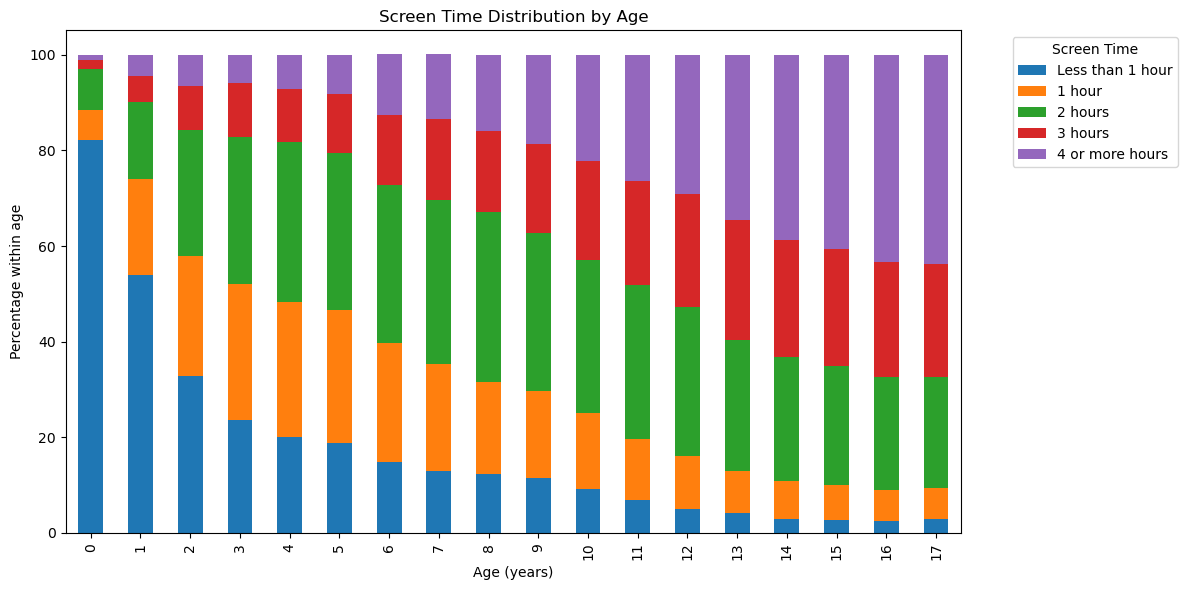

In [11]:
age_screen = screen_time_percent_table(df_cluster, "sc_age_years")
display(age_screen)

age_screen.plot(kind="bar", stacked=True, figsize=(12, 6))
plt.xlabel("Age (years)")
plt.ylabel("Percentage within age")
plt.title("Screen Time Distribution by Age")
plt.legend(
    title="Screen Time",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


Higher screen-time categories become more common among older children. Age looks useful for this project.


#### Sex


In [12]:
display(
    screen_time_percent_table(
        df_cluster,
        "sc_sex"
    )
)


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Male,13.8,15.0,27.7,18.5,25.0
Female,14.5,15.8,28.6,18.2,22.9


The screen-time percentages are quite similar between male and female children.


#### Family


In [13]:
display(
    screen_time_percent_table(
        df_cluster,
        "family_r"
    )
)


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
"Two biological/adoptive parents, married",16.7,16.9,28.7,17.3,20.4
"Two biological/adoptive parents, not married",15.4,16.1,27.9,18.4,22.2
"Two parents, at least one not biological/adoptive, married",4.8,9.0,24.4,21.1,40.7
"Two parents, at least one not biological/adoptive, not married",5.2,10.4,27.6,21.4,35.5
Single mother,8.5,12.4,26.5,21.0,31.5
Single father,7.7,12.2,29.7,20.2,30.2
Grandparent household,6.5,9.2,26.5,21.9,35.9
Other relation,12.2,10.6,26.8,18.8,31.7


Family groups show some differences in screen time, but a few groups are small.


#### Health Variables


In [14]:
health_vars = [
    "blindness",
    "eyedoctor",
    "k4q22_r",
    "k4q23"
]

for var in health_vars:
    print(f"\n--- Screen time by {var} (%) ---")
    display(
        screen_time_percent_table(
            df_cluster,
            var
        )
    )



--- Screen time by blindness (%) ---


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Yes,8.6,10.5,22.7,18.2,40.0
No,14.2,15.4,28.2,18.4,23.8



--- Screen time by eyedoctor (%) ---


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Yes,7.8,12.6,28.0,20.9,30.7
No,19.1,17.6,28.3,16.4,18.7



--- Screen time by k4q22_r (%) ---


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Received treatment,5.6,9.4,24.0,21.9,39.1
"No treatment, but needed it",6.3,8.0,24.2,20.0,41.6
"No treatment, did not need it",15.8,16.6,29.0,17.7,20.9



--- Screen time by k4q23 (%) ---


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Yes,3.9,8.6,23.1,22.7,41.7
No,15.3,16.2,28.7,17.9,21.9


`k4q22_r` and `k4q23` show noticeable differences. `blindness` should be read carefully because the Yes group is small.


#### Sleep


In [15]:
display(
    screen_time_percent_table(
        df_cluster,
        "sleep_hours"
    )
)


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
sleep_hours,,,,,
1.0,8.2,6.4,15.5,11.8,58.1
2.0,5.0,5.8,20.5,21.7,47.0
3.0,4.6,9.3,26.7,23.7,35.6
4.0,5.5,11.8,31.5,21.7,29.4
5.0,11.5,17.2,30.6,19.4,21.2
6.0,20.7,22.4,28.0,14.0,14.9
7.0,48.5,19.6,17.2,6.6,8.1


Screen time changes across sleep categories, but the sleep codes are not exact hours.


#### Curiosity vs Screen Time


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Always,19.3,18.6,30.0,15.7,16.4
Usually,9.6,13.5,28.8,21.6,26.6
Sometimes,4.5,7.2,19.8,21.2,47.2
Never,7.8,7.0,13.2,16.7,55.3


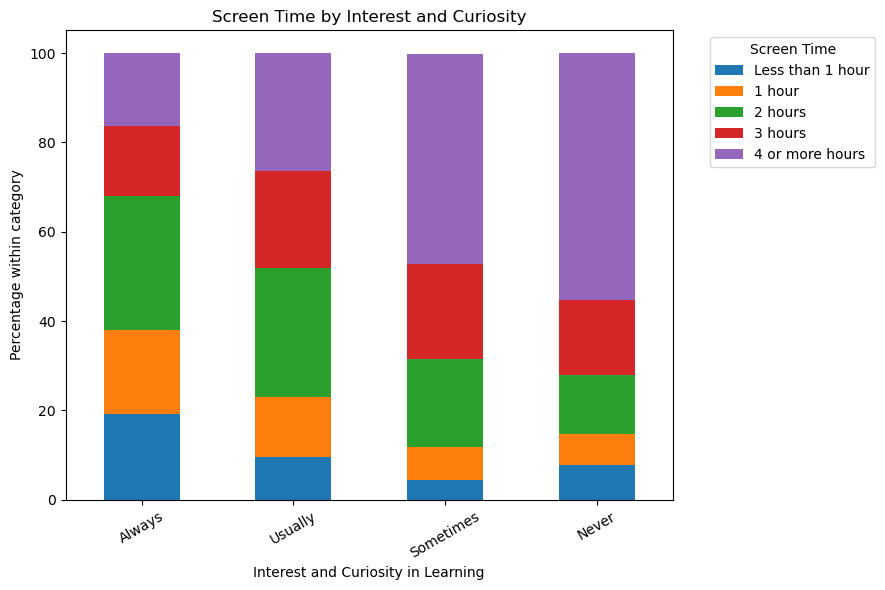

In [16]:
curiosity_screen = screen_time_percent_table(
    df_cluster,
    "k6q71_r"
)

display(curiosity_screen)

curiosity_screen.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6)
)

plt.xlabel("Interest and Curiosity in Learning")
plt.ylabel("Percentage within category")
plt.title("Screen Time by Interest and Curiosity")
plt.legend(
    title="Screen Time",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


Higher screen-time categories become more common as interest and curiosity are reported less often.


#### Education


In [17]:
display(
    screen_time_percent_table(
        df_cluster,
        "higrade"
    )
)


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Less than high school,15.3,11.0,27.8,18.2,27.7
High school,9.2,12.3,29.1,20.2,29.1
More than high school,14.8,15.9,28.0,18.1,23.2


Education level shows some differences, but one category is much more common than the others.


#### Food Situation vs Screen Time


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Always afford good nutritious meals,16.3,16.5,28.9,17.3,21.0
"Enough food, but not always the kinds we should eat",8.9,12.8,26.9,21.1,30.3
Sometimes could not afford enough,7.9,11.1,24.0,20.5,36.6
Often could not afford enough,9.7,11.8,17.2,17.2,44.1


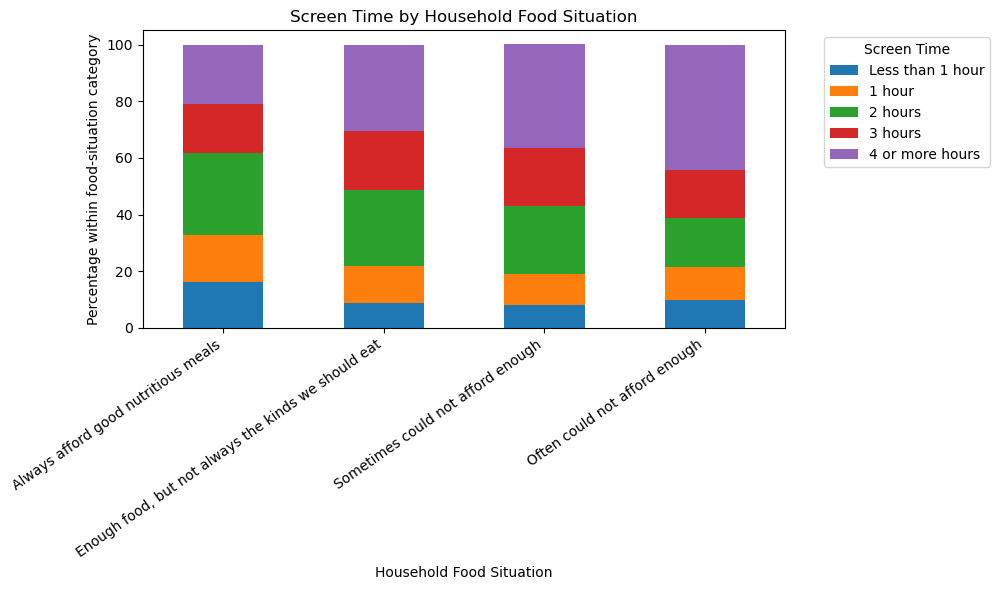

In [18]:
food_screen = screen_time_percent_table(
    df_cluster,
    "foodsit"
)

display(food_screen)

food_screen.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("Household Food Situation")
plt.ylabel("Percentage within food-situation category")
plt.title("Screen Time by Household Food Situation")
plt.legend(
    title="Screen Time",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


Higher screen-time categories are more common in households with more difficulty affording food.


#### Neighborhood Variables


In [19]:
neighborhood_vars = [
    "k10q12",
    "k10q13",
    "k10q14"
]

for var in neighborhood_vars:
    print(f"\n--- Screen time by {var} (%) ---")
    display(
        screen_time_percent_table(
            df_cluster,
            var
        )
    )



--- Screen time by k10q12 (%) ---


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Yes,14.8,15.7,28.6,18.0,23.0
No,12.1,14.4,26.9,19.6,27.1



--- Screen time by k10q13 (%) ---


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Yes,14.7,16.1,27.2,18.3,23.6
No,13.6,14.7,29.0,18.4,24.3



--- Screen time by k10q14 (%) ---


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Yes,14.5,15.7,28.8,18.1,22.9
No,13.3,14.8,26.8,18.9,26.2


The neighborhood variables show smaller differences than several other variables. `k10q13` shows especially little change.


### Step 6: Relationship Analysis

Some variables may contain similar information.

Selected crosstabs are used because most variables are categorical or ordinal.


In [20]:
def labeled_percent_crosstab(df, row_var, col_var):
    table = pd.crosstab(
        df[row_var],
        df[col_var],
        normalize="index"
    ) * 100

    if row_var in label_maps:
        table.index = [
            label_maps[row_var].get(x, str(x))
            for x in table.index
        ]

    if col_var in label_maps:
        table.columns = [
            label_maps[col_var].get(x, str(x))
            for x in table.columns
        ]

    return table.round(1)

relationship_pairs = [
    ("higrade", "foodsit"),
    ("family_r", "foodsit"),
    ("k4q22_r", "k4q23"),
    ("k10q12", "k10q13"),
    ("k10q12", "k10q14"),
    ("k10q13", "k10q14")
]

for row_var, col_var in relationship_pairs:
    print(f"\n--- {row_var} vs {col_var} (%) ---")
    display(
        labeled_percent_crosstab(
            df_cluster,
            row_var,
            col_var
        )
    )



--- higrade vs foodsit (%) ---


,Always afford good nutritious meals,"Enough food, but not always the kinds we should eat",Sometimes could not afford enough,Often could not afford enough
Less than high school,56.1,31.0,11.1,1.8
High school,49.1,40.9,8.5,1.5
More than high school,74.8,22.5,2.3,0.4



--- family_r vs foodsit (%) ---


,Always afford good nutritious meals,"Enough food, but not always the kinds we should eat",Sometimes could not afford enough,Often could not afford enough
"Two biological/adoptive parents, married",78.2,19.9,1.6,0.2
"Two biological/adoptive parents, not married",52.8,38.9,7.5,0.8
"Two parents, at least one not biological/adoptive, married",62.7,32.6,4.2,0.6
"Two parents, at least one not biological/adoptive, not married",53.8,39.0,6.2,1.0
Single mother,51.9,37.9,8.6,1.6
Single father,65.6,29.1,4.7,0.6
Grandparent household,58.6,35.2,4.8,1.4
Other relation,58.0,33.8,6.6,1.6



--- k4q22_r vs k4q23 (%) ---


,Yes,No
Received treatment,47.5,52.5
"No treatment, but needed it",23.3,76.7
"No treatment, did not need it",3.8,96.2


... (2 outputs left out)


--- k10q12 vs k10q14 (%) ---


,Yes,No
Yes,80.4,19.6
No,27.3,72.7



--- k10q13 vs k10q14 (%) ---


,Yes,No
Yes,91.8,8.2
No,46.6,53.4


Possible overlap appears between `k4q22_r` and `k4q23`, and also among the three neighborhood variables.

These variables should be reviewed before clustering.


### Step 7: Variable Quality / Feature Assessment

The variables are reviewed using the EDA results.

No variable is removed automatically.


In [21]:
feature_review = pd.DataFrame([
    [
        "sc_age_years",
        "Clear screen-time pattern",
        "Strong candidate"
    ],
    [
        "sc_sex",
        "Balanced, but small screen-time difference",
        "Review"
    ],
    [
        "family_r",
        "Some useful differences; a few small groups",
        "Keep, review rare groups"
    ],
    [
        "blindness",
        "Very small Yes group",
        "Review imbalance"
    ],
    [
        "eyedoctor",
        "Some screen-time difference",
        "Potentially useful"
    ],
    [
        "k4q22_r",
        "Noticeable screen-time differences",
        "Potentially useful; review overlap"
    ],
    [
        "k4q23",
        "Noticeable screen-time differences",
        "Potentially useful; review overlap"
    ],
    [
        "screentime",
        "Main project variable with good variation",
        "Keep"
    ],
    [
        "sleep_hours",
        "Useful pattern but different T1/T2/T3 hour ranges",
        "Review coding"
    ],
    [
        "k6q71_r",
        "Clear ordered pattern",
        "Strong candidate"
    ],
    [
        "higrade",
        "One dominant category",
        "Review"
    ],
    [
        "foodsit",
        "Clear ordered pattern; rare severe groups",
        "Strong candidate, review rare groups"
    ],
    [
        "k10q12",
        "Small screen-time difference",
        "Review redundancy"
    ],
    [
        "k10q13",
        "Very small screen-time difference",
        "Review first"
    ],
    [
        "k10q14",
        "Small screen-time difference",
        "Review redundancy"
    ]
], columns=[
    "Variable",
    "EDA Evidence",
    "Recommendation"
])

display(feature_review)


,Variable,EDA Evidence,Recommendation
0,sc_age_years,Clear screen-time pattern,Strong candidate
1,sc_sex,"Balanced, but small screen-time difference",Review
2,family_r,Some useful differences; a few small groups,"Keep, review rare groups"
3,blindness,Very small Yes group,Review imbalance
4,eyedoctor,Some screen-time difference,Potentially useful
5,k4q22_r,Noticeable screen-time differences,Potentially useful; review overlap
6,k4q23,Noticeable screen-time differences,Potentially useful; review overlap
7,screentime,Main project variable with good variation,Keep
8,sleep_hours,Useful pattern but different T1/T2/T3 hour ranges,Review coding
9,k6q71_r,Clear ordered pattern,Strong candidate


Main variables to review are `blindness`, `sleep_hours`, `higrade`, and the neighborhood variables.

`sc_age_years`, `family_r`, `k6q71_r`, `foodsit`, and the mental-health variables show more useful screen-time patterns.

No clustering is done in this section.
